# 01 — Exploratory analysis of the Olist dataset

Phase 2 exploration. Every number and chart below is computed from `data/raw` by the cells in
this notebook, using the same functions as the quality report
(`data_engineering/quality/`) and the rules in `config/business_rules.yaml`.

Re-run from the repo root:
`uv run --group notebooks jupyter nbconvert --to notebook --execute --inplace notebooks/exploration/01_exploratory_analysis.ipynb`

> The data is historical (2016–2018, Brazil). Nothing here describes current business.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

from data_engineering.business_rules import get_rules
from data_engineering.config import get_settings
from data_engineering.quality import analysis as a
from data_engineering.quality.loader import load_raw

rules = get_rules()
raw = load_raw(get_settings().raw_dir)
start, end, end_source = a.resolve_window(raw, rules)
print(f"Analysis window: {start} -> {end} ({end_source})")

# Reference palette (light mode): one hue for single-series charts, fixed order for categories.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
TEXT, TEXT2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": TEXT2,
    "axes.titlecolor": TEXT, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "xtick.color": TEXT2, "ytick.color": TEXT2, "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
})
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
brl_k = FuncFormatter(lambda v, _: f"R$ {v / 1e3:,.0f}k")

Analysis window: 2017-01-01 -> 2018-08-21 (override)


## 1. Coverage and the analysis window

Daily order counts across the whole extract. The shaded band is the analysis window from
`business_rules.yaml`; outside it the series is sparse (2016) or truncated (late 2018).

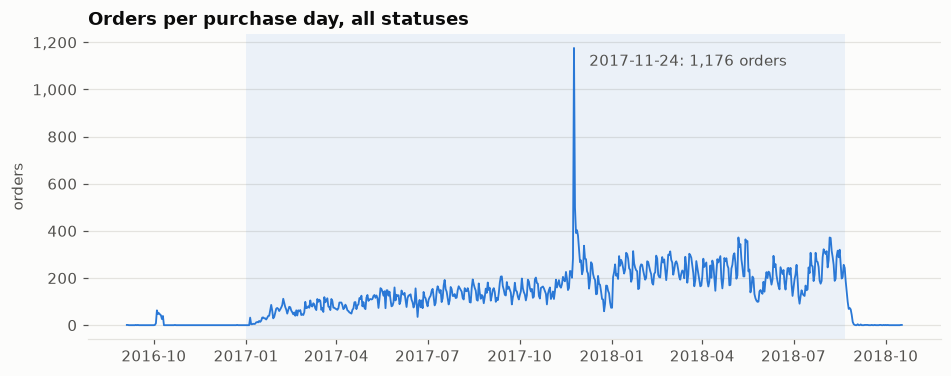

In window: 598 days, 98,390 of 99,441 orders; zero-order days in window: 4
Top 5 days: {'2017-11-24': 1176, '2017-11-25': 499, '2017-11-27': 403, '2017-11-26': 391, '2017-11-28': 380}


In [2]:
daily = a.daily_orders(raw["orders"])
fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SERIES[0], alpha=0.08, lw=0)
ax.plot(daily.index, daily.values, color=SERIES[0], lw=1.2)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Orders per purchase day, all statuses")
ax.set_ylabel("orders")
peak = daily.idxmax()
ax.annotate(f"{peak:%Y-%m-%d}: {daily.max():,} orders", (peak, daily.max()),
            xytext=(10, -4), textcoords="offset points", color=TEXT2, va="top")
plt.show()

w = daily[str(start):str(end)]
print(f"In window: {len(w)} days, {int(w.sum()):,} of {int(daily.sum()):,} orders; "
      f"zero-order days in window: {int((w == 0).sum())}")
print("Top 5 days:", {str(k.date()): int(v) for k, v in w.nlargest(5).items()})

### End-of-extract truncation

Daily volume collapses in the last days of August 2018. Ratio = day's orders ÷ median of the
previous 28 days. Weekends normally dip to about 0.7, so a weekday below that marks the start
of the truncation. The window end is pinned to the last clearly complete day.

In [3]:
baseline = daily.shift(1).rolling(28).median()
tail = pd.DataFrame({"orders": daily, "baseline_28d_median": baseline, "ratio": (daily / baseline).round(2)})
tail["weekday"] = tail.index.day_name().str[:3]
tail.loc["2018-08-13":"2018-09-03"]

,orders,baseline_28d_median,ratio,weekday
order_purchase_timestamp,,,,
2018-08-13,292,262.0,1.11,Mon
2018-08-14,316,269.5,1.17,Tue
2018-08-15,288,273.5,1.05,Wed
2018-08-16,320,273.5,1.17,Thu
2018-08-17,257,282.0,0.91,Fri
2018-08-18,198,282.0,0.70,Sat
2018-08-19,204,282.0,0.72,Sun
2018-08-20,256,282.0,0.91,Mon
2018-08-21,243,273.5,0.89,Tue


## 2. Revenue (GMV) by month

GMV = Σ(price + freight) over order items, for orders whose status counts as revenue
(`revenue.include_statuses`). August 2018 is partial (ends at the window end) and drawn lighter.

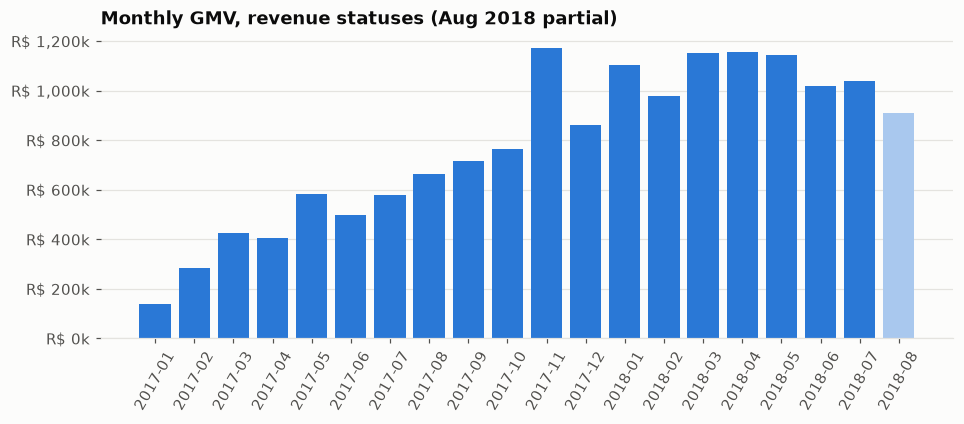

order_purchase_timestamp,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
gmv_brl,"136,943.46","283,561.69","425,617.96","405,848.61","582,710.83","499,652.24","578,753.73","661,903.52","717,102.72","764,756.03","1,172,191.68","861,526.77","1,101,920.01","979,486.16","1,152,656.99","1,156,248.89","1,145,686.46","1,020,381.90","1,039,783.58","908,846.90"


In [4]:
rev_status = set(rules.revenue.include_statuses)
o = raw["orders"]
orders_rev = o[o["order_status"].isin(rev_status)]
gmv = (raw["order_items"].assign(gmv=lambda d: d["price"] + d["freight_value"])
       .merge(orders_rev[["order_id", "order_purchase_timestamp"]], on="order_id"))
gmv = gmv[gmv["order_purchase_timestamp"].between(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), inclusive="left")]
monthly = gmv.groupby(gmv["order_purchase_timestamp"].dt.to_period("M"))["gmv"].sum()

fig, ax = plt.subplots()
colors = [SERIES[0]] * (len(monthly) - 1) + ["#a9c8ee"]
ax.bar(monthly.index.astype(str), monthly.values, color=colors, width=0.8)
ax.yaxis.set_major_formatter(brl_k)
ax.set_title("Monthly GMV, revenue statuses (Aug 2018 partial)")
ax.tick_params(axis="x", rotation=60)
plt.show()
monthly.map("{:,.2f}".format).to_frame("gmv_brl").T

## 3. Customers: how many buy again?

In [5]:
opc = a.repeat_customer_summary(raw)
dist = opc.value_counts().sort_index()
print(f"{len(opc):,} customers; {int((opc >= 2).sum()):,} ({(opc >= 2).mean():.2%}) placed 2+ orders")
dist.rename("customers").to_frame().T

96,096 customers; 2,997 (3.12%) placed 2+ orders


orders,1,2,3,4,5,6,7,9,17
customers,93099,2745,203,30,8,6,3,1,1


With about 97% of customers buying once, "churn" in the usual sense would be almost
everyone. This is why Phase 6 models **repurchase propensity** instead (see business_rules.md).

## 4. Delivery performance

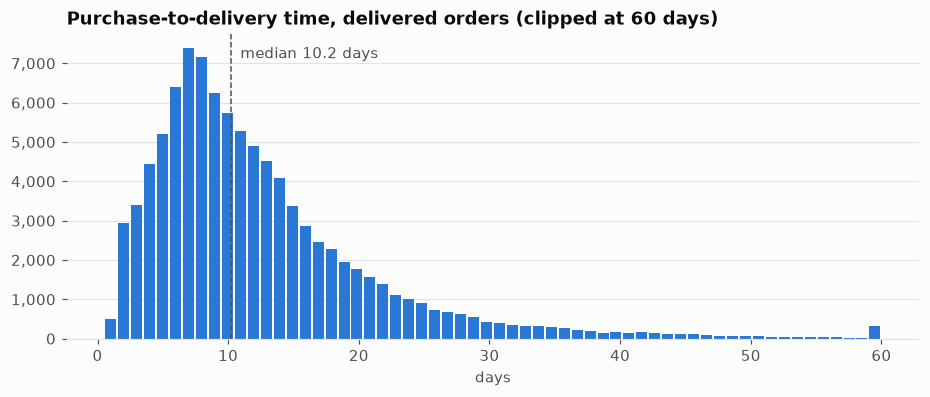

96,282 delivered orders with consistent timestamps; 306 took more than 60 days (max 209.6)


In [6]:
dlv = a.delivery_frame(raw, rules)
fig, ax = plt.subplots()
ax.hist(dlv["delivery_days"].clip(upper=60), bins=60, color=SERIES[0], rwidth=0.85)
med = dlv["delivery_days"].median()
ax.axvline(med, color=TEXT2, lw=1, ls="--")
ax.annotate(f"median {med:.1f} days", (med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=TEXT2)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Purchase-to-delivery time, delivered orders (clipped at 60 days)")
ax.set_xlabel("days")
plt.show()
print(f"{len(dlv):,} delivered orders with consistent timestamps; "
      f"{int((dlv['delivery_days'] > 60).sum()):,} took more than 60 days (max {dlv['delivery_days'].max():.1f})")

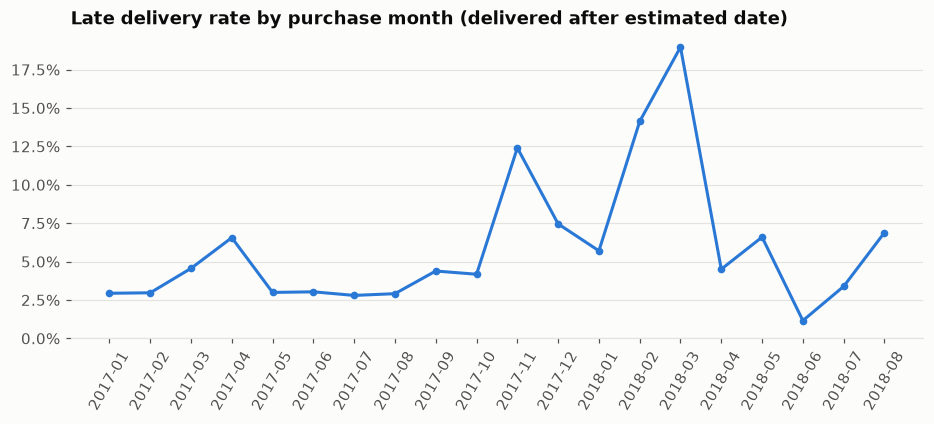

Note: the last month is right-censored - orders still in transit at extract time are missing,
so delivery KPIs exclude cohorts younger than 30 days.


,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
late_rate,2.9%,3.0%,4.6%,6.6%,3.0%,3.0%,2.8%,2.9%,4.4%,4.2%,12.4%,7.5%,5.7%,14.1%,19.0%,4.5%,6.6%,1.2%,3.4%,6.9%


In [7]:
late_m = (dlv[dlv["order_purchase_timestamp"].between(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), inclusive="left")]
          .groupby(lambda i: dlv.loc[i, "order_purchase_timestamp"].to_period("M"))["is_late"].mean())
fig, ax = plt.subplots()
ax.plot(late_m.index.astype(str), late_m.values, color=SERIES[0], marker="o", ms=4)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(bottom=0)
ax.set_title("Late delivery rate by purchase month (delivered after estimated date)")
ax.tick_params(axis="x", rotation=60)
plt.show()
print("Note: the last month is right-censored - orders still in transit at extract time are missing,")
print(f"so delivery KPIs exclude cohorts younger than {rules.delivery.cohort_maturity_days} days.")
late_m.map("{:.1%}".format).to_frame("late_rate").T

## 5. Late delivery and review score

Per-order score uses the configured rule (`reviews.per_order_score`). The comparison is
descriptive: lateness and low scores move together here, which is not a causal estimate.

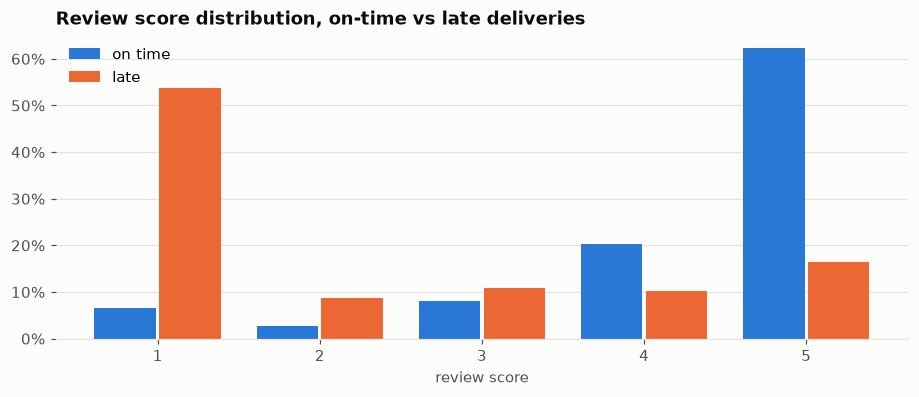

,count,mean
is_late,,
False,89258,4.291
True,6379,2.270


In [8]:
rv = a.per_order_review(raw["order_reviews"], rules.reviews.per_order_score)
sc = dlv[["order_id", "is_late"]].merge(rv, on="order_id")
share = (sc.groupby("is_late")["review_score"].value_counts(normalize=True)
         .unstack(0).rename(columns={False: "on time", True: "late"}))
fig, ax = plt.subplots()
x = range(1, 6)
ax.bar([i - 0.2 for i in x], share["on time"], width=0.38, color=SERIES[0], label="on time")
ax.bar([i + 0.2 for i in x], share["late"], width=0.38, color=SERIES[1], label="late")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(list(x))
ax.set_xlabel("review score")
ax.set_title("Review score distribution, on-time vs late deliveries")
ax.legend(loc="upper left")
plt.show()
sc.groupby("is_late")["review_score"].agg(["count", "mean"]).round(3)

## 6. Categories and regions (revenue statuses, analysis window)

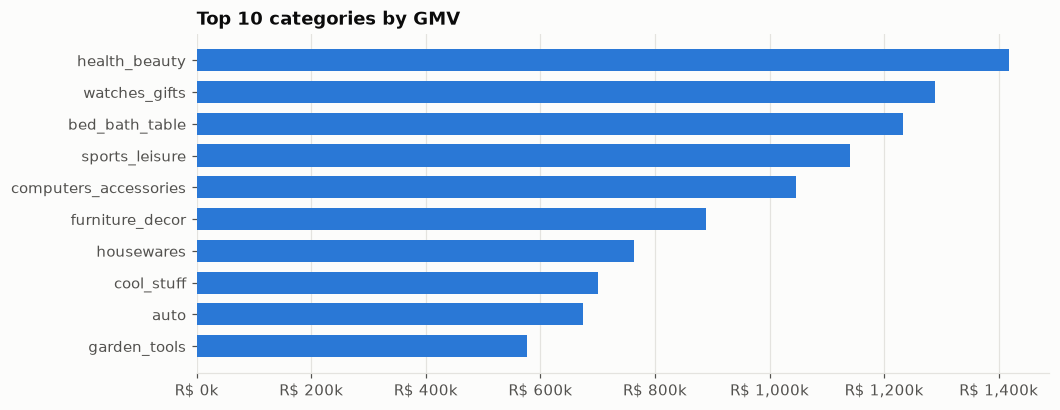

In [9]:
pr = raw["products"].copy()
tr = dict(zip(raw["category_translation"]["product_category_name"],
              raw["category_translation"]["product_category_name_english"]))
tr.update(rules.products.extra_translations)
pr["category"] = pr["product_category_name"].map(tr).fillna(rules.products.unknown_category)
cat = gmv.merge(pr[["product_id", "category"]], on="product_id").groupby("category")["gmv"].sum().nlargest(10)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(cat.index[::-1], cat.values[::-1], color=SERIES[0], height=0.7)
ax.xaxis.set_major_formatter(brl_k)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Top 10 categories by GMV")
plt.show()

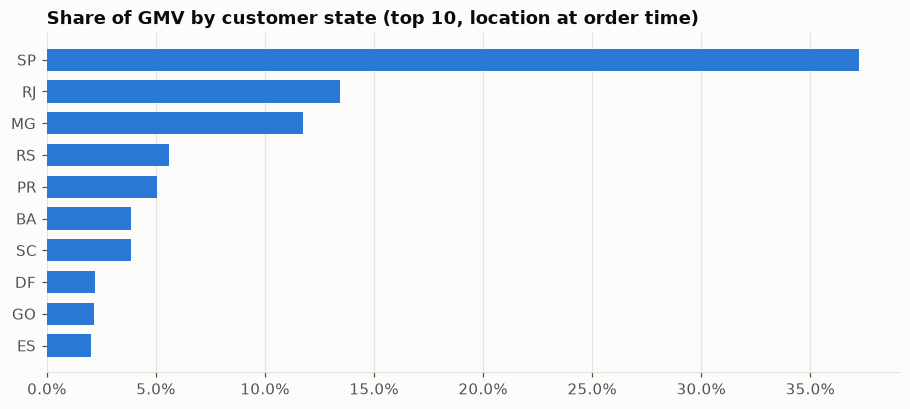

In [10]:
cust_state = raw["customers"].set_index("customer_id")["customer_state"]
st = (gmv.assign(state=gmv["order_id"].map(o.set_index("order_id")["customer_id"]).map(cust_state))
      .groupby("state")["gmv"].sum())
st_share = (st / st.sum()).nlargest(10)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(st_share.index[::-1], st_share.values[::-1], color=SERIES[0], height=0.7)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Share of GMV by customer state (top 10, location at order time)")
plt.show()

## 7. Sparsity for recommendations

In [11]:
it = raw["order_items"]
sold = it.groupby("product_id").size()
cust_items = (it.merge(o[["order_id", "customer_id"]], on="order_id")
              .merge(raw["customers"][["customer_id", "customer_unique_id"]], on="customer_id")
              .groupby("customer_unique_id")["product_id"].nunique())
print(f"Products sold: {len(sold):,}; sold exactly once: {(sold == 1).mean():.2%}")
print(f"Customers with 2+ distinct products: {int((cust_items >= 2).sum()):,} ({(cust_items >= 2).mean():.2%})")
n_c, n_p = len(cust_items), len(sold)
print(f"Customer x product matrix density: {cust_items.sum() / (n_c * n_p):.6%}")

Products sold: 32,951; sold exactly once: 54.98%
Customers with 2+ distinct products: 5,456 (5.72%)
Customer x product matrix density: 0.003244%


## Takeaways (feed into Phase 3+)

See [docs/business_rules.md](../../docs/business_rules.md) for the decisions these findings
justify, and [docs/data_quality_report.md](../../docs/data_quality_report.md) for the full check
results.